# Midterm Review

## Training, validation, and testing

- **Training data:** used to learn the model's weights.
- **Validation data:** used to compare models and select an architecture.
- **Test data:** used once, after choosing the model.

The same observations must be used when comparing different architectures on the same dataset. Means and standard deviations are calculated from training data only.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

---
# 1. Banknote authentication

**Prediction:** Genuine (0) or forged (1).

Each banknote has four measurements: `Variance`, `Skewness`, `Kurtosis`, and `Entropy`.

Data: [UCI Banknote Authentication](https://archive.ics.uci.edu/dataset/267/banknote+authentication).

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

banknotes = pd.read_csv(url, names=["Variance", "Skewness", "Kurtosis", "Entropy", "Forged"])
print(banknotes.shape)
print(banknotes["Forged"].value_counts())
banknotes.head()

(1372, 5)
Forged
0    762
1    610
Name: count, dtype: int64


,Variance,Skewness,Kurtosis,Entropy,Forged
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


### The original two-feature problem

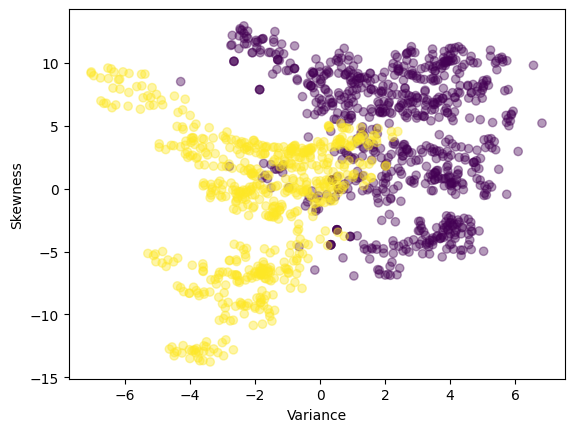

In [ ]:
plt.scatter(banknotes["Variance"], banknotes["Skewness"], c=banknotes["Forged"], alpha=0.4)
plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.show()

### Divide the data into training (70%), validation (15%), and test (15%)

In [ ]:
banknotes = banknotes.sample(frac=1, random_state=42).reset_index(drop=True)

n = len(banknotes)
bank_train = banknotes.iloc[:int(0.70*n)]
bank_val = banknotes.iloc[int(0.70*n):int(0.85*n)]
bank_test = banknotes.iloc[int(0.85*n):]

y_bank_train = bank_train["Forged"].to_numpy()
y_bank_val = bank_val["Forged"].to_numpy()
y_bank_test = bank_test["Forged"].to_numpy()

print(len(bank_train), len(bank_val), len(bank_test))

960 206 206


### Train with two features

Both features are standardized using the training-set mean and standard deviation:

$$x_{\mathrm{standardized}}=\frac{x-\mathrm{mean}}{\mathrm{standard\ deviation}}$$

In [ ]:
two_features = ["Variance", "Skewness"]

mean = bank_train[two_features].mean()
sd = bank_train[two_features].std()

X_bank_train_2 = ((bank_train[two_features] - mean) / sd).to_numpy(dtype="float32")
X_bank_val_2 = ((bank_val[two_features] - mean) / sd).to_numpy(dtype="float32")

print(X_bank_train_2.shape)

(960, 2)


In [ ]:
bank_2_simple = keras.Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(1, activation="sigmoid")
])

bank_2_simple.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

history_bank_2_simple = bank_2_simple.fit(
    X_bank_train_2, y_bank_train,
    validation_data=(X_bank_val_2, y_bank_val),
    epochs=50
)

Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1375 - loss: 1.3119 - val_accuracy: 0.1456 - val_loss: 1.2933
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1396 - loss: 1.2839 - val_accuracy: 0.1602 - val_loss: 1.2671
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1406 - loss: 1.2562 - val_accuracy: 0.1602 - val_loss: 1.2414
Epoch 4/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1448 - loss: 1.2290 - val_accuracy: 0.1602 - val_loss: 1.2160
Epoch 5/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1469 - loss: 1.2023 - val_accuracy: 0.1650 - val_loss: 1.1911
Epoch 6/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1479 - loss: 1.1761 - val_accuracy: 0.1650 - val_loss: 1.1667
Epoch 7/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1510 - loss: 1.1505 - val_accuracy: 0.1699 - val_loss: 1.1428
Epoch 8/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1500 - loss: 1.1254 - val_accuracy: 0.1748 - val_loss

In [ ]:
bank_2_hidden = keras.Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(4, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

bank_2_hidden.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

history_bank_2_hidden = bank_2_hidden.fit(
    X_bank_train_2, y_bank_train,
    validation_data=(X_bank_val_2, y_bank_val),
    epochs=50
)

Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.1937 - loss: 0.7649 - val_accuracy: 0.2087 - val_loss: 0.7320
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2552 - loss: 0.7181 - val_accuracy: 0.3204 - val_loss: 0.6950
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4740 - loss: 0.6767 - val_accuracy: 0.5194 - val_loss: 0.6628
Epoch 4/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5781 - loss: 0.6409 - val_accuracy: 0.5340 - val_loss: 0.6347
Epoch 5/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6531 - loss: 0.6094 - val_accuracy: 0.6456 - val_loss: 0.6095
Epoch 6/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6938 - loss: 0.5812 - val_accuracy: 0.6699 - val_loss: 0.5859
Epoch 7/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7396 - loss: 0.5552 - val_accuracy: 0.7476 - val_loss: 0.5633
Epoch 8/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7865 - loss: 0.5308 - val_accuracy: 0.7864 - val_loss

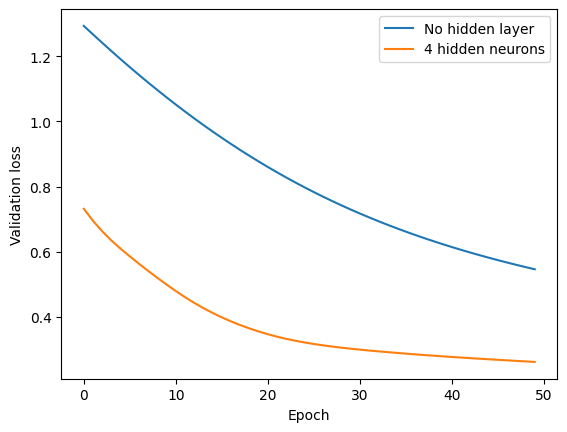

In [ ]:
plt.plot(history_bank_2_simple.history["val_loss"], label="No hidden layer")
plt.plot(history_bank_2_hidden.history["val_loss"], label="4 hidden neurons")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.legend()
plt.show()

### Train with all four features

The same neuron now has four inputs:

$$z=w_1x_1+w_2x_2+w_3x_3+w_4x_4+b$$

A model using more than two inputs cannot be fully represented by one two-dimensional decision-boundary plot.

In [ ]:
four_features = ["Variance", "Skewness", "Kurtosis", "Entropy"]

mean = bank_train[four_features].mean()
sd = bank_train[four_features].std()

X_bank_train = ((bank_train[four_features] - mean) / sd).to_numpy(dtype="float32")
X_bank_val = ((bank_val[four_features] - mean) / sd).to_numpy(dtype="float32")
X_bank_test = ((bank_test[four_features] - mean) / sd).to_numpy(dtype="float32")

print(X_bank_train.shape)

(960, 4)


In [ ]:
bank_simple = keras.Sequential([
    layers.Input(shape=(4,)),
    layers.Dense(1, activation="sigmoid")
])

bank_simple.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

history_bank_simple = bank_simple.fit(
    X_bank_train, y_bank_train,
    validation_data=(X_bank_val, y_bank_val),
    epochs=50
)

Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.1667 - loss: 1.0967 - val_accuracy: 0.1456 - val_loss: 1.0885
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1615 - loss: 1.0674 - val_accuracy: 0.1262 - val_loss: 1.0613
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1562 - loss: 1.0390 - val_accuracy: 0.1359 - val_loss: 1.0350
Epoch 4/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1573 - loss: 1.0117 - val_accuracy: 0.1408 - val_loss: 1.0097
Epoch 5/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1573 - loss: 0.9855 - val_accuracy: 0.1311 - val_loss: 0.9853
Epoch 6/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1448 - loss: 0.9604 - val_accuracy: 0.1408 - val_loss: 0.9619
Epoch 7/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1542 - loss: 0.9364 - val_accuracy: 0.1408 - val_loss: 0.9395
Epoch 8/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1760 - loss: 0.9135 - val_accuracy: 0.1408 - val_loss:

In [ ]:
bank_hidden = keras.Sequential([
    layers.Input(shape=(4,)),
    layers.Dense(4, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

bank_hidden.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

history_bank_hidden = bank_hidden.fit(
    X_bank_train, y_bank_train,
    validation_data=(X_bank_val, y_bank_val),
    epochs=50
)

Epoch 1/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1771 - loss: 0.8427 - val_accuracy: 0.2136 - val_loss: 0.8057
Epoch 2/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2240 - loss: 0.7973 - val_accuracy: 0.2621 - val_loss: 0.7638
Epoch 3/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2771 - loss: 0.7547 - val_accuracy: 0.3398 - val_loss: 0.7245
Epoch 4/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3906 - loss: 0.7150 - val_accuracy: 0.4709 - val_loss: 0.6875
Epoch 5/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5531 - loss: 0.6776 - val_accuracy: 0.6068 - val_loss: 0.6529
Epoch 6/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6542 - loss: 0.6427 - val_accuracy: 0.6893 - val_loss: 0.6207
Epoch 7/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7260 - loss: 0.6105 - val_accuracy: 0.7573 - val_loss: 0.5905
Epoch 8/50
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7802 - loss: 0.5803 - val_accuracy: 0.7961 - val_loss

### Compare validation results

Two inputs, no hidden layer: 0.7135922312736511
Two inputs, hidden layer: 0.8883495330810547
Four inputs, no hidden layer: 0.8300970792770386
Four inputs, hidden layer: 0.9708737730979919


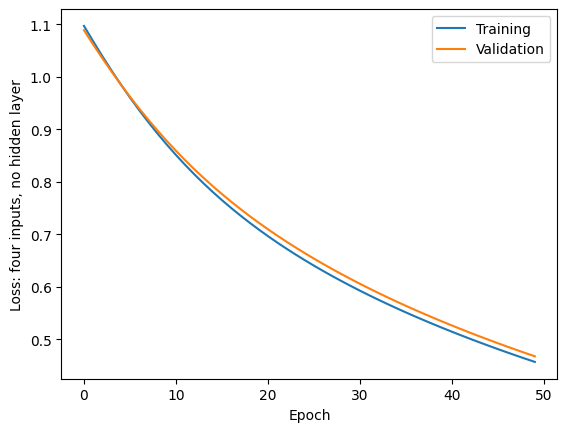

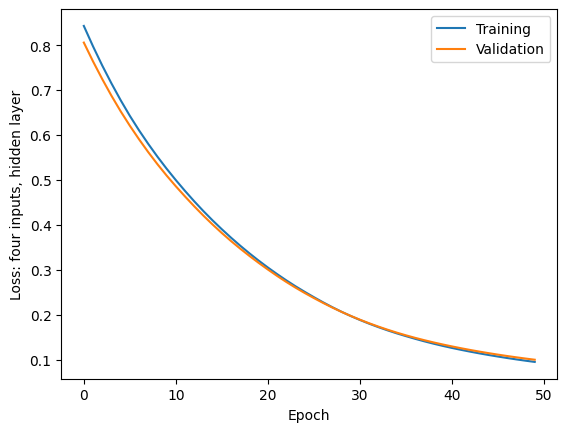

In [ ]:
print("Two inputs, no hidden layer:", history_bank_2_simple.history["val_accuracy"][-1])
print("Two inputs, hidden layer:", history_bank_2_hidden.history["val_accuracy"][-1])
print("Four inputs, no hidden layer:", history_bank_simple.history["val_accuracy"][-1])
print("Four inputs, hidden layer:", history_bank_hidden.history["val_accuracy"][-1])

plt.plot(history_bank_simple.history["loss"], label="Training")
plt.plot(history_bank_simple.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss: four inputs, no hidden layer")
plt.legend()
plt.show()

plt.plot(history_bank_hidden.history["loss"], label="Training")
plt.plot(history_bank_hidden.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss: four inputs, hidden layer")
plt.legend()
plt.show()

### Select an architecture using validation loss, then evaluate on test data

In [ ]:
if history_bank_simple.history["val_loss"][-1] < history_bank_hidden.history["val_loss"][-1]:
    best_bank = bank_simple
    print("Selected: no hidden layer")
else:
    best_bank = bank_hidden
    print("Selected: four hidden neurons")

bank_test_loss, bank_test_accuracy = best_bank.evaluate(X_bank_test, y_bank_test)
print("Test accuracy:", bank_test_accuracy)

Selected: four hidden neurons
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9854 - loss: 0.0761 
Test accuracy: 0.9854369163513184


---
# 2. College placement

**Prediction:** Not placed (0) or placed (1).

The original models used `CGPA` and `Internships`. The dataset has seven predictors in total.

Data: [Placement Predictor dataset](https://github.com/Avi8010/Placement_Predictor).

In [ ]:
url = "https://raw.githubusercontent.com/Avi8010/Placement_Predictor/main/collegePlace.csv"
placement = pd.read_csv(url)
print(placement.shape)
print(placement.columns.tolist())
placement.head()

(2966, 8)
['Age', 'Gender', 'Stream', 'Internships', 'CGPA', 'Hostel', 'HistoryOfBacklogs', 'PlacedOrNot']


,Age,Gender,Stream,Internships,CGPA,Hostel,HistoryOfBacklogs,PlacedOrNot
0,22,Male,Electronics And Communication,1,8,1,1,1
1,21,Female,Computer Science,0,7,1,1,1
2,22,Female,Information Technology,1,6,0,0,1
3,21,Male,Information Technology,0,8,0,1,1
4,22,Male,Mechanical,0,8,1,0,1


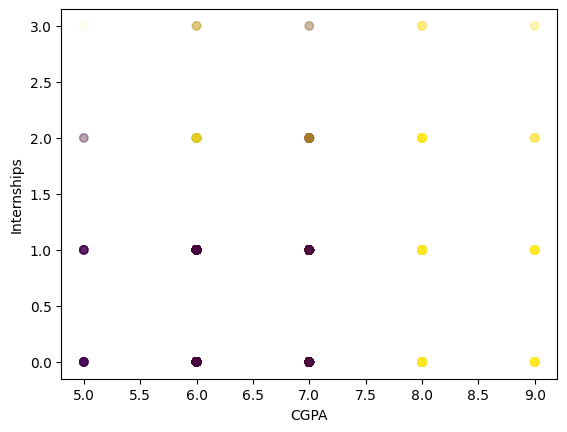

In [ ]:
plt.scatter(placement["CGPA"], placement["Internships"], c=placement["PlacedOrNot"], alpha=0.05)
plt.xlabel("CGPA")
plt.ylabel("Internships")
plt.show()

### Train, validation, and test sets

In [ ]:
placement = placement.sample(frac=1, random_state=42).reset_index(drop=True)

n = len(placement)
placement_train = placement.iloc[:int(0.70*n)]
placement_val = placement.iloc[int(0.70*n):int(0.85*n)]
placement_test = placement.iloc[int(0.85*n):]

y_placement_train = placement_train["PlacedOrNot"].to_numpy()
y_placement_val = placement_val["PlacedOrNot"].to_numpy()
y_placement_test = placement_test["PlacedOrNot"].to_numpy()

print(len(placement_train), len(placement_val), len(placement_test))

2076 445 445


### Train with CGPA and internships

In [ ]:
features = ["CGPA", "Internships"]
mean = placement_train[features].mean()
sd = placement_train[features].std()

X_placement_train_2 = ((placement_train[features] - mean) / sd).to_numpy(dtype="float32")
X_placement_val_2 = ((placement_val[features] - mean) / sd).to_numpy(dtype="float32")

In [ ]:
placement_2_simple = keras.Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(1, activation="sigmoid")
])

placement_2_simple.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history_placement_2_simple = placement_2_simple.fit(
    X_placement_train_2, y_placement_train,
    validation_data=(X_placement_val_2, y_placement_val),
    epochs=50
)

Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7331 - loss: 0.5263 - val_accuracy: 0.7124 - val_loss: 0.5413
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7331 - loss: 0.5151 - val_accuracy: 0.7124 - val_loss: 0.5313
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7331 - loss: 0.5058 - val_accuracy: 0.7124 - val_loss: 0.5229
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7331 - loss: 0.4980 - val_accuracy: 0.7124 - val_loss: 0.5159
Epoch 5/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7119 - loss: 0.4914 - val_accuracy: 0.6719 - val_loss: 0.5100
Epoch 6/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6777 - loss: 0.4858 - val_accuracy: 0.6764 - val_loss: 0.5051
Epoch 7/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6845 - loss: 0.4811 - val_accuracy: 0.6764 - val_loss: 0.5009
Epoch 8/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6845 - loss: 0.4772 - val_accuracy: 0.6764 - val_loss:

In [ ]:
placement_2_hidden = keras.Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(4, activation="relu"),
    layers.Dense(6, activation="relu"),
    layers.Dense(10, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

placement_2_hidden.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history_placement_2_hidden = placement_2_hidden.fit(
    X_placement_train_2, y_placement_train,
    validation_data=(X_placement_val_2, y_placement_val),
    epochs=50
)

Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5549 - loss: 0.6273 - val_accuracy: 0.5618 - val_loss: 0.5915
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6272 - loss: 0.5543 - val_accuracy: 0.6989 - val_loss: 0.5247
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7596 - loss: 0.4853 - val_accuracy: 0.8292 - val_loss: 0.4606
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8487 - loss: 0.4288 - val_accuracy: 0.8292 - val_loss: 0.4190
Epoch 5/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8487 - loss: 0.3946 - val_accuracy: 0.8292 - val_loss: 0.3949
Epoch 6/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8487 - loss: 0.3744 - val_accuracy: 0.8292 - val_loss: 0.3809
Epoch 7/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8487 - loss: 0.3623 - val_accuracy: 0.8292 - val_loss: 0.3728
Epoch 8/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8487 - loss: 0.3556 - val_accuracy: 0.8292 - val_loss:

In [ ]:
print("Two inputs, no hidden layer:", history_placement_2_simple.history["val_accuracy"][-1])
print("Two inputs, hidden layers:", history_placement_2_hidden.history["val_accuracy"][-1])

Two inputs, no hidden layer: 0.766292154788971
Two inputs, hidden layers: 0.8292135000228882


### Use all seven predictors

`Age`, `CGPA`, and `Internships` are numbers. `Hostel` and `HistoryOfBacklogs` are already 0/1 values. `Gender` and `Stream` are categories and must be converted to numerical columns.

One-hot encoding adds one 0/1 column for each category. The input size is therefore the number of columns **after** encoding, not necessarily seven.

In [ ]:
# Keep only input columns.
X_placement_train = placement_train.drop(columns="PlacedOrNot")
X_placement_val = placement_val.drop(columns="PlacedOrNot")
X_placement_test = placement_test.drop(columns="PlacedOrNot")

# Convert category names to 0/1 columns.
X_placement_train = pd.get_dummies(X_placement_train, dtype=int)
X_placement_val = pd.get_dummies(X_placement_val, dtype=int)
X_placement_test = pd.get_dummies(X_placement_test, dtype=int)

# Give each set the same columns as the training set.
X_placement_val = X_placement_val.reindex(columns=X_placement_train.columns, fill_value=0)
X_placement_test = X_placement_test.reindex(columns=X_placement_train.columns, fill_value=0)

print(X_placement_train.columns.tolist())

['Age', 'Internships', 'CGPA', 'Hostel', 'HistoryOfBacklogs', 'Gender_Female', 'Gender_Male', 'Stream_Civil', 'Stream_Computer Science', 'Stream_Electrical', 'Stream_Electronics And Communication', 'Stream_Information Technology', 'Stream_Mechanical']


In [ ]:
numeric = ["Age", "CGPA", "Internships"]
mean = X_placement_train[numeric].mean()
sd = X_placement_train[numeric].std()

X_placement_train = X_placement_train.copy()
X_placement_val = X_placement_val.copy()
X_placement_test = X_placement_test.copy()

X_placement_train[numeric] = (X_placement_train[numeric] - mean) / sd
X_placement_val[numeric] = (X_placement_val[numeric] - mean) / sd
X_placement_test[numeric] = (X_placement_test[numeric] - mean) / sd

X_placement_train = X_placement_train.to_numpy(dtype="float32")
X_placement_val = X_placement_val.to_numpy(dtype="float32")
X_placement_test = X_placement_test.to_numpy(dtype="float32")

print("Original predictors: 7")
print("Inputs after encoding:", X_placement_train.shape[1])

Original predictors: 7
Inputs after encoding: 13


### Compare a small and a large model

In [ ]:
number_of_inputs = X_placement_train.shape[1]

placement_small = keras.Sequential([
    layers.Input(shape=(number_of_inputs,)),
    layers.Dense(4, activation="relu"),
    layers.Dense(6, activation="relu"),
    layers.Dense(10, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

placement_small.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history_placement_small = placement_small.fit(
    X_placement_train, y_placement_train,
    validation_data=(X_placement_val, y_placement_val),
    epochs=50
)

Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5857 - loss: 0.6697 - val_accuracy: 0.6135 - val_loss: 0.6507
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6305 - loss: 0.6272 - val_accuracy: 0.6831 - val_loss: 0.6043
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7317 - loss: 0.5656 - val_accuracy: 0.7146 - val_loss: 0.5370
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7601 - loss: 0.4907 - val_accuracy: 0.7438 - val_loss: 0.4683
Epoch 5/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7779 - loss: 0.4338 - val_accuracy: 0.7685 - val_loss: 0.4260
Epoch 6/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7876 - loss: 0.4006 - val_accuracy: 0.7753 - val_loss: 0.3981
Epoch 7/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7962 - loss: 0.3793 - val_accuracy: 0.7775 - val_loss: 0.3803
Epoch 8/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7938 - loss: 0.3663 - val_accuracy: 0.7798 - val_loss:

In [ ]:
placement_large = keras.Sequential([
    layers.Input(shape=(number_of_inputs,)),
    layers.Dense(50, activation="relu"),
    layers.Dense(20, activation="relu"),
    layers.Dense(10, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

placement_large.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history_placement_large = placement_large.fit(
    X_placement_train, y_placement_train,
    validation_data=(X_placement_val, y_placement_val),
    epochs=50
)

Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7543 - loss: 0.5935 - val_accuracy: 0.7798 - val_loss: 0.4973
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7818 - loss: 0.4321 - val_accuracy: 0.7910 - val_loss: 0.4138
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8015 - loss: 0.3752 - val_accuracy: 0.8292 - val_loss: 0.3833
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8478 - loss: 0.3441 - val_accuracy: 0.8337 - val_loss: 0.3632
Epoch 5/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8584 - loss: 0.3247 - val_accuracy: 0.8315 - val_loss: 0.3515
Epoch 6/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8656 - loss: 0.3130 - val_accuracy: 0.8315 - val_loss: 0.3453
Epoch 7/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8675 - loss: 0.3047 - val_accuracy: 0.8337 - val_loss: 0.3412
Epoch 8/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8714 - loss: 0.2984 - val_accuracy: 0.8337 - val_loss:

Small model validation accuracy: 0.8449438214302063
Large model validation accuracy: 0.8741573095321655


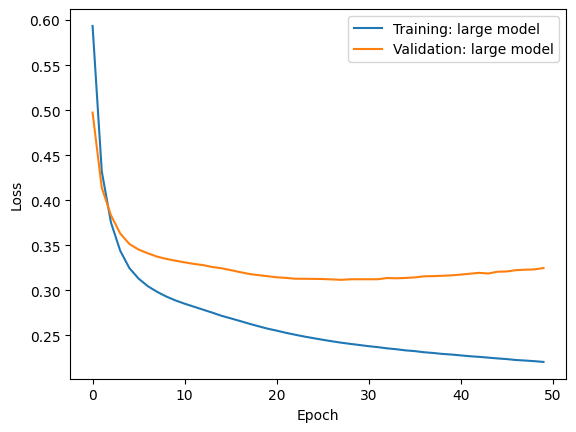

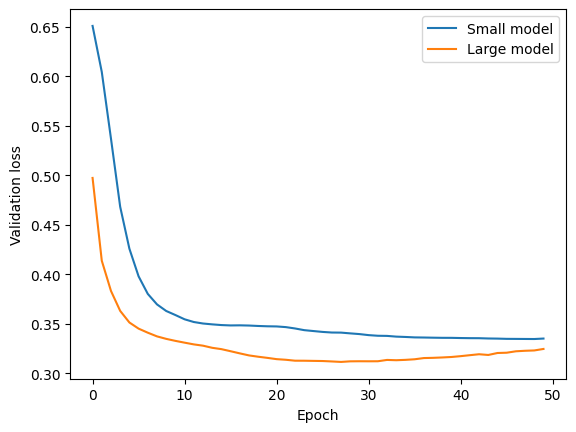

In [ ]:
print("Small model validation accuracy:", history_placement_small.history["val_accuracy"][-1])
print("Large model validation accuracy:", history_placement_large.history["val_accuracy"][-1])

plt.plot(history_placement_large.history["loss"], label="Training: large model")
plt.plot(history_placement_large.history["val_loss"], label="Validation: large model")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.plot(history_placement_small.history["val_loss"], label="Small model")
plt.plot(history_placement_large.history["val_loss"], label="Large model")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.legend()
plt.show()

In [ ]:
if history_placement_small.history["val_loss"][-1] < history_placement_large.history["val_loss"][-1]:
    best_placement = placement_small
    print("Selected: small model")
else:
    best_placement = placement_large
    print("Selected: large model")

placement_test_loss, placement_test_accuracy = best_placement.evaluate(X_placement_test, y_placement_test)
print("Test accuracy:", placement_test_accuracy)

Selected: large model
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8899 - loss: 0.2656 
Test accuracy: 0.8898876309394836


In [ ]:
probabilities = best_placement.predict(X_placement_test[:5])

for i in range(5):
    print("Actual:", y_placement_test[i], "Probability of placement:", probabilities[i][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
Actual: 0 Probability of placement: 0.041121326
Actual: 0 Probability of placement: 0.1450391
Actual: 1 Probability of placement: 0.20564061
Actual: 0 Probability of placement: 0.01734595
Actual: 0 Probability of placement: 0.086690135


---
# 3. Fashion-MNIST

**Prediction:** One of ten clothing categories.

Each image has 28 × 28 = 784 pixel values. The `Flatten` layer turns each image into 784 inputs. The final layer has ten softmax outputs.

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28)
(10000, 28, 28)


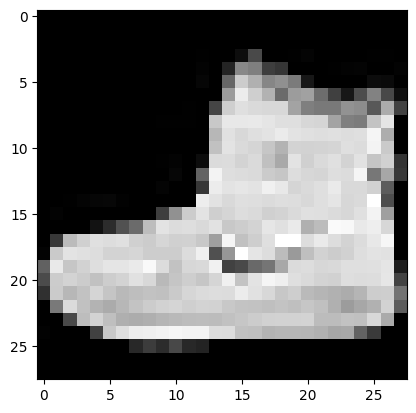

In [ ]:
(images, labels), (test_images, test_labels) = keras.datasets.fashion_mnist.load_data()

fashion_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print(images.shape)
print(test_images.shape)
plt.imshow(images[0], cmap="gray")
plt.show()

### Normalize and separate training from validation images

In [ ]:
images = images.astype("float32") / 255
test_images = test_images.astype("float32") / 255

In [ ]:
np.random.seed(42)
order = np.random.permutation(len(images))

cut = int(0.80 * len(images))
train_indices = order[:cut]
val_indices = order[cut:]

X_fashion_train = images[train_indices]
y_fashion_train = labels[train_indices]
X_fashion_val = images[val_indices]
y_fashion_val = labels[val_indices]

print(X_fashion_train.shape)
print(X_fashion_val.shape)
print(test_images.shape)

(48000, 28, 28)
(12000, 28, 28)
(10000, 28, 28)


### Two neural networks with different hidden-layer sizes

In [ ]:
fashion_small = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

fashion_small.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_fashion_small = fashion_small.fit(
    X_fashion_train, y_fashion_train,
    validation_data=(X_fashion_val, y_fashion_val),
    epochs=12
)

Epoch 1/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8185 - loss: 0.5170 - val_accuracy: 0.8514 - val_loss: 0.4268
Epoch 2/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8618 - loss: 0.3853 - val_accuracy: 0.8629 - val_loss: 0.3920
Epoch 3/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8740 - loss: 0.3446 - val_accuracy: 0.8653 - val_loss: 0.3823
Epoch 4/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8823 - loss: 0.3189 - val_accuracy: 0.8712 - val_loss: 0.3647
Epoch 5/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8893 - loss: 0.2988 - val_accuracy: 0.8723 - val_loss: 0.3676
Epoch 6/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8945 - loss: 0.2841 - val_accuracy: 0.8737 - val_loss: 0.3605
Epoch 7/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8996 - loss: 0.2693 - val_accuracy: 0.8763 - val_loss: 0.3570
Epoch 8/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9036 - loss: 0.2577 -

In [ ]:
fashion_large = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax")
])

fashion_large.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_fashion_large = fashion_large.fit(
    X_fashion_train, y_fashion_train,
    validation_data=(X_fashion_val, y_fashion_val),
    epochs=12
)

Epoch 1/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8215 - loss: 0.5060 - val_accuracy: 0.8535 - val_loss: 0.4147
Epoch 2/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8644 - loss: 0.3763 - val_accuracy: 0.8662 - val_loss: 0.3849
Epoch 3/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8783 - loss: 0.3353 - val_accuracy: 0.8692 - val_loss: 0.3766
Epoch 4/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8865 - loss: 0.3088 - val_accuracy: 0.8727 - val_loss: 0.3629
Epoch 5/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8942 - loss: 0.2875 - val_accuracy: 0.8773 - val_loss: 0.3448
Epoch 6/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9002 - loss: 0.2713 - val_accuracy: 0.8797 - val_loss: 0.3470
Epoch 7/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9057 - loss: 0.2551 - val_accuracy: 0.8830 - val_loss: 0.3375
Epoch 8/12
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9115 - loss: 0.2

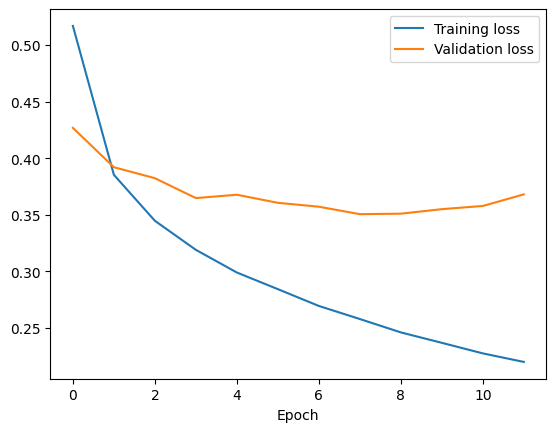

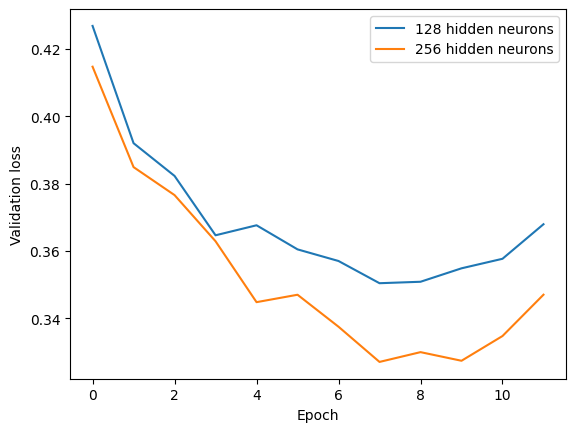

In [ ]:
plt.plot(history_fashion_small.history["loss"], label="Training loss")
plt.plot(history_fashion_small.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.legend()
plt.show()

plt.plot(history_fashion_small.history["val_loss"], label="128 hidden neurons")
plt.plot(history_fashion_large.history["val_loss"], label="256 hidden neurons")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.legend()
plt.show()

In [ ]:
if history_fashion_small.history["val_loss"][-1] < history_fashion_large.history["val_loss"][-1]:
    best_fashion = fashion_small
    print("Selected: 128 hidden neurons")
else:
    best_fashion = fashion_large
    print("Selected: 256 hidden neurons")

fashion_test_loss, fashion_test_accuracy = best_fashion.evaluate(test_images, test_labels)
print("Test accuracy:", fashion_test_accuracy)

Selected: 256 hidden neurons
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8806 - loss: 0.3896
Test accuracy: 0.8805999755859375


### Examine predictions on unseen test images

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


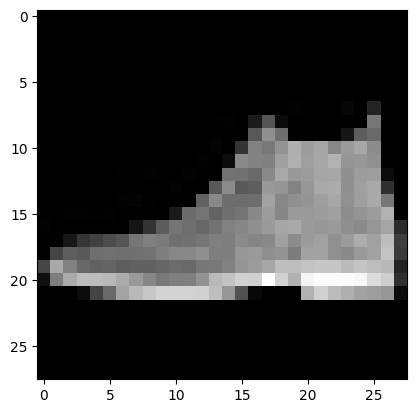

Actual class: Ankle boot
Predicted class: Ankle boot


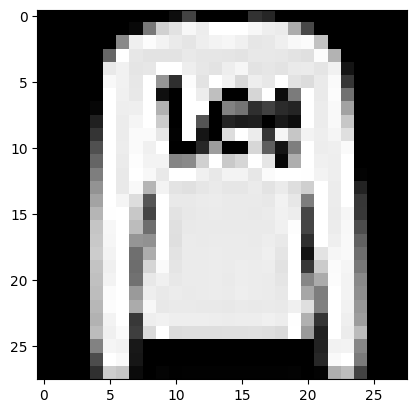

Actual class: Pullover
Predicted class: Pullover


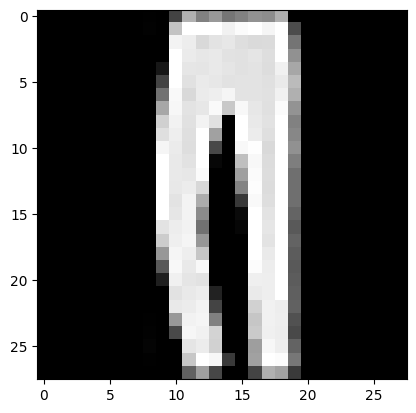

Actual class: Trouser
Predicted class: Trouser


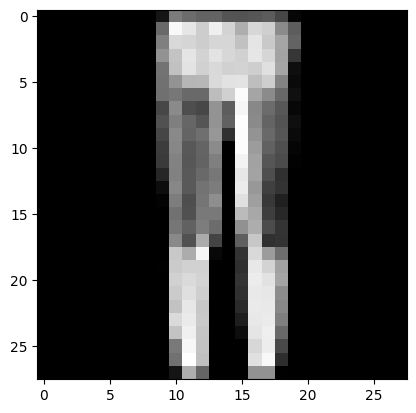

Actual class: Trouser
Predicted class: Trouser


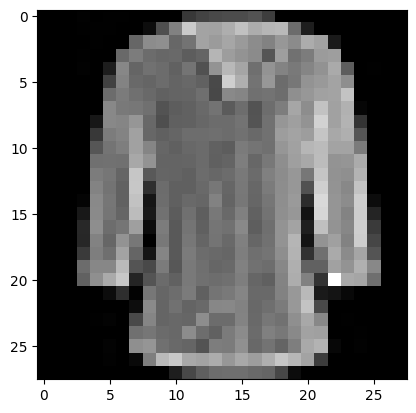

Actual class: Shirt
Predicted class: Shirt


In [ ]:
probabilities = best_fashion.predict(test_images)
predictions = np.argmax(probabilities, axis=1)

for i in range(5):
    plt.imshow(test_images[i], cmap="gray")
    plt.show()
    print("Actual class:", fashion_names[test_labels[i]])
    print("Predicted class:", fashion_names[predictions[i]])

Incorrect predictions: 1194


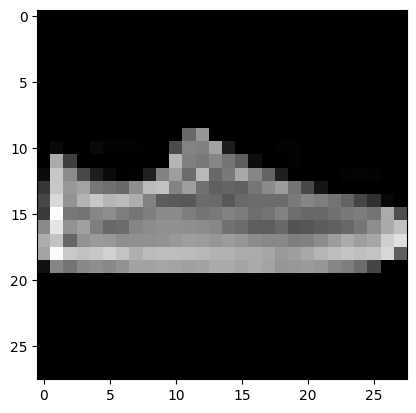

Actual: Sneaker
Predicted: Sandal


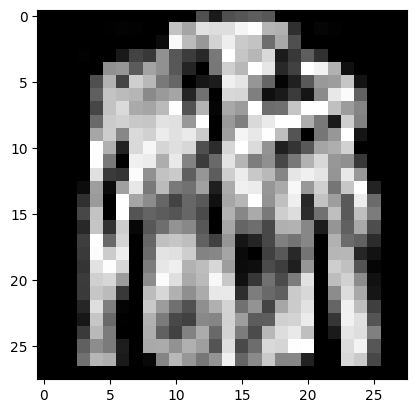

Actual: Coat
Predicted: Pullover


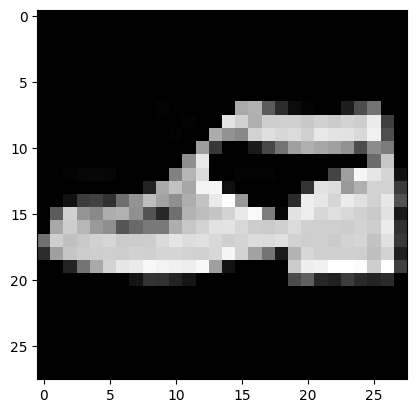

Actual: Ankle boot
Predicted: Sandal


In [ ]:
mistakes = np.where(predictions != test_labels)[0]
print("Incorrect predictions:", len(mistakes))

for i in mistakes[:3]:
    plt.imshow(test_images[i], cmap="gray")
    plt.show()
    print("Actual:", fashion_names[test_labels[i]])
    print("Predicted:", fashion_names[predictions[i]])

---
# 4. Student academic outcomes

**Prediction:** `Dropout`, `Enrolled`, or `Graduate`.

Nine predictors are used, including admission information and first-semester performance. Second-semester information is not used.

Data: [UCI Predict Students' Dropout and Academic Success](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success).

The following CSV is a public copy of the dataset.

In [ ]:
url = "https://raw.githubusercontent.com/alalyyy/student-dropout-prediction/main/data.csv"

outcomes = pd.read_csv(url, sep=";", encoding="utf-8-sig")
outcomes.columns = outcomes.columns.str.strip()

print(outcomes.shape)
print(outcomes.columns.tolist())
print(outcomes["Target"].value_counts())
outcomes.head()

(4424, 37)
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target']
Ta

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


### Select the input features and the target

In [ ]:
numeric = [
    "Admission grade",
    "Age at enrollment",
    "Application order",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)"
]

categorical = ["Course", "Scholarship holder", "Daytime/evening attendance"]

outcomes = outcomes[numeric + categorical + ["Target"]].copy()
outcomes["Target"] = outcomes["Target"].str.strip()
outcomes.head()

,Admission grade,Age at enrollment,Application order,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Course,Scholarship holder,Daytime/evening attendance,Target
0,127.3,20,5,0,0,0.000000,171,0,1,Dropout
1,142.5,19,1,6,6,14.000000,9254,0,1,Graduate
2,124.8,19,5,6,0,0.000000,9070,0,1,Dropout
3,119.6,20,2,6,6,13.428571,9773,0,1,Graduate
4,141.5,45,1,6,5,12.333333,8014,0,0,Graduate


### Divide the observations

In [ ]:
outcomes = outcomes.sample(frac=1, random_state=42).reset_index(drop=True)

n = len(outcomes)
outcome_train = outcomes.iloc[:int(0.70*n)]
outcome_val = outcomes.iloc[int(0.70*n):int(0.85*n)]
outcome_test = outcomes.iloc[int(0.85*n):]

print(len(outcome_train), len(outcome_val), len(outcome_test))
print(outcome_train["Target"].value_counts())

3096 664 664
Target
Graduate    1522
Dropout     1006
Enrolled     568
Name: count, dtype: int64


### Encode categories

`Course`, `Scholarship holder`, and `Daytime/evening attendance` represent categories, even though the CSV stores them as numbers. Converting them to text before `get_dummies` makes each category a separate 0/1 input.

In [ ]:
# Numerical columns remain numerical.
X_outcome_train = outcome_train[numeric].copy()
X_outcome_val = outcome_val[numeric].copy()
X_outcome_test = outcome_test[numeric].copy()

# One-hot encoding for the three categorical columns.
train_categories = pd.get_dummies(outcome_train[categorical].astype(str), dtype=int)
val_categories = pd.get_dummies(outcome_val[categorical].astype(str), dtype=int)
test_categories = pd.get_dummies(outcome_test[categorical].astype(str), dtype=int)

val_categories = val_categories.reindex(columns=train_categories.columns, fill_value=0)
test_categories = test_categories.reindex(columns=train_categories.columns, fill_value=0)

X_outcome_train = pd.concat([X_outcome_train, train_categories], axis=1)
X_outcome_val = pd.concat([X_outcome_val, val_categories], axis=1)
X_outcome_test = pd.concat([X_outcome_test, test_categories], axis=1)

print(X_outcome_train.shape)
print(X_outcome_train.columns.tolist())

(3096, 27)
['Admission grade', 'Age at enrollment', 'Application order', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Course_171', 'Course_33', 'Course_8014', 'Course_9003', 'Course_9070', 'Course_9085', 'Course_9119', 'Course_9130', 'Course_9147', 'Course_9238', 'Course_9254', 'Course_9500', 'Course_9556', 'Course_9670', 'Course_9773', 'Course_9853', 'Course_9991', 'Scholarship holder_0', 'Scholarship holder_1', 'Daytime/evening attendance_0', 'Daytime/evening attendance_1']


### Standardize numerical inputs using training-set statistics

In [ ]:
mean = X_outcome_train[numeric].mean()
sd = X_outcome_train[numeric].std()

X_outcome_train[numeric] = (X_outcome_train[numeric] - mean) / sd
X_outcome_val[numeric] = (X_outcome_val[numeric] - mean) / sd
X_outcome_test[numeric] = (X_outcome_test[numeric] - mean) / sd

X_outcome_train = X_outcome_train.to_numpy(dtype="float32")
X_outcome_val = X_outcome_val.to_numpy(dtype="float32")
X_outcome_test = X_outcome_test.to_numpy(dtype="float32")

print("Number of inputs:", X_outcome_train.shape[1])

Number of inputs: 27


### Convert target labels to integers

In [ ]:
class_numbers = {"Dropout": 0, "Enrolled": 1, "Graduate": 2}
class_names = ["Dropout", "Enrolled", "Graduate"]

y_outcome_train = outcome_train["Target"].map(class_numbers).to_numpy()
y_outcome_val = outcome_val["Target"].map(class_numbers).to_numpy()
y_outcome_test = outcome_test["Target"].map(class_numbers).to_numpy()

print(y_outcome_train[:10])

[0 2 2 2 0 2 1 0 2 2]


### Baseline: always predict the most frequent class

In [ ]:
common_class = outcome_train["Target"].mode()[0]
baseline_accuracy = (outcome_val["Target"] == common_class).mean()

print("Most frequent class:", common_class)
print("Baseline validation accuracy:", baseline_accuracy)

Most frequent class: Graduate
Baseline validation accuracy: 0.5195783132530121


### Multiclass neural networks

For three classes, the output layer uses three softmax neurons. Labels 0, 1, and 2 can be used directly with `sparse_categorical_crossentropy`.

In [ ]:
number_of_inputs = X_outcome_train.shape[1]

outcome_simple = keras.Sequential([
    layers.Input(shape=(number_of_inputs,)),
    layers.Dense(3, activation="softmax")
])

outcome_simple.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_outcome_simple = outcome_simple.fit(
    X_outcome_train, y_outcome_train,
    validation_data=(X_outcome_val, y_outcome_val),
    epochs=45
)

Epoch 1/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4025 - loss: 1.1254 - val_accuracy: 0.4955 - val_loss: 1.0362
Epoch 2/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5233 - loss: 0.9978 - val_accuracy: 0.5783 - val_loss: 0.9414
Epoch 3/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5872 - loss: 0.9282 - val_accuracy: 0.6205 - val_loss: 0.8876
Epoch 4/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6166 - loss: 0.8863 - val_accuracy: 0.6446 - val_loss: 0.8534
Epoch 5/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6298 - loss: 0.8580 - val_accuracy: 0.6506 - val_loss: 0.8294
Epoch 6/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6402 - loss: 0.8372 - val_accuracy: 0.6581 - val_loss: 0.8112
Epoch 7/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6495 - loss: 0.8210 - val_accuracy: 0.6627 - val_loss: 0.7965
Epoch 8/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6592 - loss: 0.8077 - val_accuracy: 0.6702 - val_loss:

In [ ]:
outcome_hidden = keras.Sequential([
    layers.Input(shape=(number_of_inputs,)),
    layers.Dense(32, activation="relu"),
    layers.Dense(3, activation="softmax")
])

outcome_hidden.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_outcome_hidden = outcome_hidden.fit(
    X_outcome_train, y_outcome_train,
    validation_data=(X_outcome_val, y_outcome_val),
    epochs=45
)

Epoch 1/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6008 - loss: 0.9423 - val_accuracy: 0.6837 - val_loss: 0.8158
Epoch 2/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6699 - loss: 0.7952 - val_accuracy: 0.6913 - val_loss: 0.7463
Epoch 3/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6928 - loss: 0.7424 - val_accuracy: 0.7063 - val_loss: 0.7078
Epoch 4/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7093 - loss: 0.7117 - val_accuracy: 0.7154 - val_loss: 0.6845
Epoch 5/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7180 - loss: 0.6924 - val_accuracy: 0.7319 - val_loss: 0.6696
Epoch 6/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7209 - loss: 0.6791 - val_accuracy: 0.7319 - val_loss: 0.6598
Epoch 7/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7267 - loss: 0.6699 - val_accuracy: 0.7289 - val_loss: 0.6529
Epoch 8/45
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7277 - loss: 0.6633 - val_accuracy: 0.7289 - val_loss:

No hidden layer validation accuracy: 0.7183734774589539
32-neuron model validation accuracy: 0.7484939694404602
Majority-class baseline: 0.5195783132530121


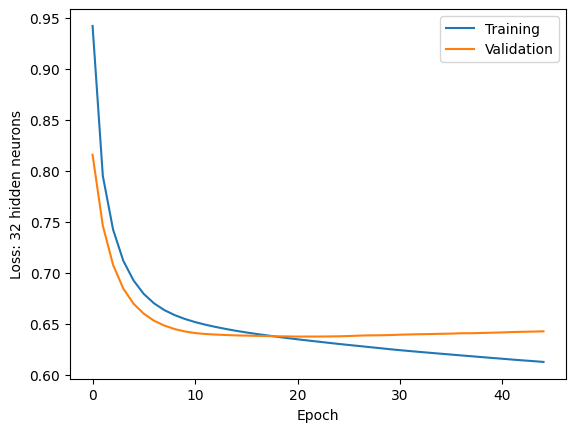

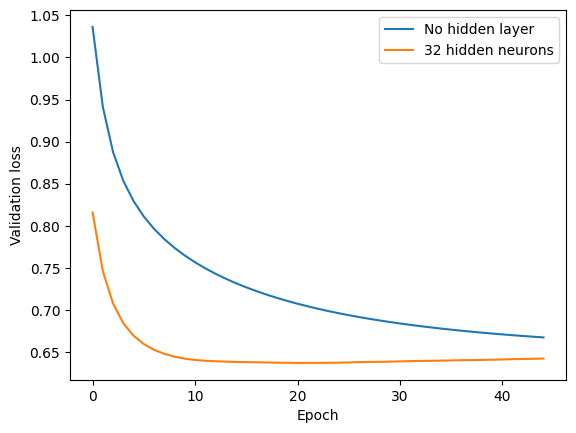

In [ ]:
print("No hidden layer validation accuracy:", history_outcome_simple.history["val_accuracy"][-1])
print("32-neuron model validation accuracy:", history_outcome_hidden.history["val_accuracy"][-1])
print("Majority-class baseline:", baseline_accuracy)

plt.plot(history_outcome_hidden.history["loss"], label="Training")
plt.plot(history_outcome_hidden.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss: 32 hidden neurons")
plt.legend()
plt.show()

plt.plot(history_outcome_simple.history["val_loss"], label="No hidden layer")
plt.plot(history_outcome_hidden.history["val_loss"], label="32 hidden neurons")
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.legend()
plt.show()

In [ ]:
if history_outcome_simple.history["val_loss"][-1] < history_outcome_hidden.history["val_loss"][-1]:
    best_outcome = outcome_simple
    print("Selected: no hidden layer")
else:
    best_outcome = outcome_hidden
    print("Selected: 32 hidden neurons")

outcome_test_loss, outcome_test_accuracy = best_outcome.evaluate(X_outcome_test, y_outcome_test)
print("Test accuracy:", outcome_test_accuracy)

Selected: 32 hidden neurons
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7003 - loss: 0.7130 
Test accuracy: 0.7003012299537659


### Examine the three softmax probabilities

In [ ]:
probabilities = best_outcome.predict(X_outcome_test[:5])
predictions = np.argmax(probabilities, axis=1)

for i in range(5):
    print("Actual:", class_names[y_outcome_test[i]])
    print("Predicted:", class_names[predictions[i]])
    print("Probabilities:", probabilities[i])
    print("Sum:", probabilities[i].sum())
    print()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
Actual: Graduate
Predicted: Graduate
Probabilities: [0.01818732 0.03541939 0.9463933 ]
Sum: 1.0

Actual: Dropout
Predicted: Graduate
Probabilities: [0.1939197  0.06726792 0.7388123 ]
Sum: 0.99999994

Actual: Dropout
Predicted: Dropout
Probabilities: [0.5766821  0.14070192 0.282616  ]
Sum: 1.0

Actual: Graduate
Predicted: Graduate
Probabilities: [0.03988896 0.11658926 0.8435218 ]
Sum: 1.0

Actual: Graduate
Predicted: Graduate
Probabilities: [0.06792611 0.07353679 0.8585371 ]
Sum: 1.0



### Prediction errors by class

In [ ]:
all_probabilities = best_outcome.predict(X_outcome_test)
all_predictions = np.argmax(all_probabilities, axis=1)

print(pd.crosstab(
    pd.Series(y_outcome_test, name="Actual"),
    pd.Series(all_predictions, name="Predicted")
))

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Predicted    0   1    2
Actual                 
0          133  28   38
1           36  32   55
2           17  25  300


---
# Final test results

Each test result comes from a model selected using validation data. The test set was not used to choose the model.

In [ ]:
print("Banknotes:", bank_test_accuracy)
print("Placement:", placement_test_accuracy)
print("Fashion-MNIST:", fashion_test_accuracy)
print("Academic outcomes:", outcome_test_accuracy)

Banknotes: 0.9854369163513184
Placement: 0.8898876309394836
Fashion-MNIST: 0.8805999755859375
Academic outcomes: 0.7003012299537659


## Conclusions

- The banknote model can use four measurements rather than the original two.
- College-placement input columns increase after converting category names into 0/1 columns.
- Fashion-MNIST uses 784 pixel inputs, even though each image is displayed as a 28 × 28 square.
- A large network does not necessarily have lower validation loss than a smaller one.
- Training loss shows how well the model fits the training observations. Validation loss measures performance on observations not used to update the weights.
- The test set is evaluated only after choosing a model.

The student-outcomes dataset is used for a classification exercise, not for decisions about individual students.